# elstop.py

*Generated from `elstop.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
elstop.py - electronic stopping tables for LAMMPS 'fix electron/stopping'
(W / C / He, extendable) from a reusable BASIS of per-element cross sections.

Bragg's rule: for projectile p in any W-C mixture
    S_p(E) = n_W * sigma_p@W(E) + n_C * sigma_p@C(E)     [eV/A]
(sigma in eV*A^2, n in atoms/A^3), so SRIM or the RustBCA model runs once per
projectile in each pure element; any composition is then a fast sum.

Subcommands
  basis   sigma_p@t(E) on a log grid (default 10-1000 eV)
            --backend srim      pysrim -> SRIM SR module (SRIM + wine)
            --backend srimfile  SR text files you made (e.g. SRIM GUI), eV/A
            --backend rustbca   RustBCA's electronic-stopping model (transcribed)
  table   one LAMMPS table from a basis for a composition
  grid    a family of tables over C/W (if 'shell' is not allowed on compute nodes)

Examples
  python3 elstop.py basis --backend rustbca -o basis_rustbca.dat
  python3 elstop.py basis --backend srimfile --srim-file He@W "He in W.txt" --srim-file He@C "He in C.txt" -o basis_srim.dat
  python3 elstop.py table --basis basis_rustbca.dat --types W C He --target W:0.5,C:0.5 --rho 15.63 -o elstop_WC.table
  python3 elstop.py table --basis basis_rustbca.dat --types W C He --nW 0.04806 --nC 0.031 -o elstop_alt.table

Python 3.6+; 'table' and 'grid' need no numpy (fast enough every MD cycle).
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'elstop.py'
ARGS = ["basis", "--backend", "rustbca", "-o", "basis_nb.dat"]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import argparse
import math
import os
import re
import sys
import time

In [3]:
# Z, mass(amu), default solid density (g/cm3) used only for pure-element SR runs
ELEMENTS = {
    "He": (2, 4.002602, 0.125),
    "C":  (6, 12.011, 2.253),
    "Si": (14, 28.085, 2.329),
    "V":  (23, 50.9415, 6.11),
    "W":  (74, 183.84, 19.25),
}
AVOGADRO = 6.02214076e23

In [4]:
# ---------------------------------------------------------------------------
# RustBCA model (from RustBCA src/material.rs, consts.rs):
#   S_low  = 1.212 eV*A^2 * Za^(7/6) Zb / (Za^(2/3)+Zb^(2/3))^(3/2) * sqrt(E/Ma)   [E eV, Ma amu]
#   S_high = Bethe-Bloch: Zb Za^2 / beta^2 * ln(eb + 1 + B/eb), eb = 2 me v^2 / I,
#            I = Zb*I0, I0 = 12+7/Zb (Zb<13) else 9.76+58.5 Zb^-1.19 eV, B = 100 Za/Zb (Zb<3) else 5
#   INTERPOLATED (default): S = 1/(1/S_high + 1/(S_low*ck))      LOW_ENERGY_NONLOCAL: S = S_low*ck
# ---------------------------------------------------------------------------
E2 = 14.3996454784          # e^2/(4 pi eps0) in eV*A
MEC2 = 510998.95            # electron rest energy, eV
AMUC2 = 931494102.42        # amu c^2, eV
BB_PREF = 4.0 * math.pi * E2 * E2 / MEC2      # eV*A^2


def rustbca_sigma(za, ma, zb, e_ev, ck=1.0, mode="interpolated"):
    s_low = 1.212 * za ** (7.0 / 6.0) * zb / (za ** (2.0 / 3.0) + zb ** (2.0 / 3.0)) ** 1.5 \
        * math.sqrt(e_ev / ma)
    if mode == "nonlocal":
        return s_low * ck
    beta2 = 1.0 - 1.0 / (1.0 + e_ev / (ma * AMUC2)) ** 2
    i0 = 12.0 + 7.0 / zb if zb < 13 else 9.76 + 58.5 * zb ** -1.19
    big_i = zb * i0
    b = 100.0 * za / zb if zb < 3 else 5.0
    eb = 2.0 * MEC2 * beta2 / big_i
    s_high = BB_PREF * zb * za * za / beta2 * math.log(eb + 1.0 + b / eb)
    return 1.0 / (1.0 / s_high + 1.0 / (s_low * ck))

In [5]:
# ---------------------------------------------------------------------------
# SRIM output parsing (works for SR Module output and GUI "Stopping/Range Tables")
# ---------------------------------------------------------------------------
_E_UNITS = {"eV": 1.0, "keV": 1e3, "MeV": 1e6, "GeV": 1e9}


def parse_sr_file(path):
    """-> (E[eV] list, Se[eV/A] list, n_target[atoms/A^3] or None)"""
    text = open(path, encoding="latin-1").read()
    m = re.search(r"Stopping Units\s*=\s*(.+)", text)
    units = m.group(1).strip() if m else ""
    if re.fullmatch(r"eV\s*/\s*Angstrom", units):
        scale = 1.0
    elif re.fullmatch(r"keV\s*/\s*micron", units) or re.fullmatch(r"MeV\s*/\s*mm", units):
        scale = 0.1
    else:
        sys.exit("{}: stopping units '{}' not handled - rerun SR with eV/Angstrom".format(path, units))
    m = re.search(r"Density\s*=\s*[0-9.Ee+-]+\s*g/cm3\s*=\s*([0-9.Ee+-]+)\s*atoms/cm3", text)
    n_t = float(m.group(1)) * 1e-24 if m else None
    rows = []
    row_re = re.compile(r"^\s*([0-9.]+)\s+(eV|keV|MeV|GeV)\s+([0-9.Ee+-]+)\s+([0-9.Ee+-]+)")
    for line in text.splitlines():
        mm = row_re.match(line)
        if mm:
            rows.append((float(mm.group(1)) * _E_UNITS[mm.group(2)], float(mm.group(3)) * scale))
    if len(rows) < 3:
        sys.exit("{}: no stopping table rows found".format(path))
    rows.sort()
    return [r[0] for r in rows], [r[1] for r in rows], n_t


def loglog(xs, ys, x):
    """log-log interpolation; sqrt(E) (velocity-proportional) extension outside."""
    if x <= xs[0]:
        return ys[0] * math.sqrt(x / xs[0])
    if x >= xs[-1]:
        return ys[-1] * math.sqrt(x / xs[-1])
    lo, hi = 0, len(xs) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if xs[mid] <= x:
            lo = mid
        else:
            hi = mid
    t = math.log(x / xs[lo]) / math.log(xs[hi] / xs[lo])
    return math.exp(math.log(ys[lo]) + t * math.log(ys[hi] / ys[lo]))


def log_grid(emin, emax, n):
    return [emin * (emax / emin) ** (j / (n - 1.0)) for j in range(n)]

In [6]:
# ---------------------------------------------------------------------------
# basis
# ---------------------------------------------------------------------------
def run_pysrim(proj, targ, emin, emax, srim_dir):
    """One SR Module run for projectile `proj` in pure element `targ`."""
    import yaml                        # pysrim 0.5.10 calls yaml.load() without Loader,
    if not getattr(yaml, "_elstop_patched", False):     # which PyYAML>=6 rejects
        _orig = yaml.load
        yaml.load = lambda s, Loader=yaml.SafeLoader: _orig(s, Loader=Loader)
        yaml._elstop_patched = True
    from srim import Ion, Layer, SR
    import shutil
    import subprocess
    # pysrim writes SR.IN; we launch SRModule.exe and parse the output
    # ourselves (pysrim's SRResults regexes are brittle across SRIM builds).
    here = os.getcwd()
    srdir = os.path.join(srim_dir, "SR Module")
    out = os.path.join(srdir, "SR_OUTPUT.txt")
    try:
        os.chdir(srdir)
        if os.path.exists(out):
            os.remove(out)
        layer = Layer({targ: {"stoich": 1.0}}, density=ELEMENTS[targ][2], width=1.0e4)
        sr = SR(layer, Ion(proj, energy=emax), output_type=1, energy_min=emin)
        sr._write_input_file()                            # -> SR.IN in cwd
        exe = os.path.join(".", "SRModule.exe")
        wine = shutil.which("wine")
        subprocess.check_call([wine, exe] if wine else [exe])
    finally:
        os.chdir(here)
    if not os.path.exists(out):
        sys.exit("SRModule.exe produced no SR_OUTPUT.txt in {} - check wine/xvfb".format(srdir))
    return parse_sr_file(out)


def cmd_basis(a):
    es = log_grid(a.emin, a.emax, a.npts)
    keys = ["{}@{}".format(p, t) for p in a.projectiles for t in a.targets]
    cols, notes = {}, []

    if a.backend == "rustbca":
        for p in a.projectiles:
            za, ma, _ = ELEMENTS[p]
            for t in a.targets:
                zb = ELEMENTS[t][0]
                cols["{}@{}".format(p, t)] = [rustbca_sigma(za, ma, zb, e, a.ck, a.rustbca_mode) for e in es]
        worst = max(abs(1 - rustbca_sigma(ELEMENTS[p][0], ELEMENTS[p][1], ELEMENTS[t][0], a.emax, a.ck)
                        / rustbca_sigma(ELEMENTS[p][0], ELEMENTS[p][1], ELEMENTS[t][0], a.emax, a.ck, "nonlocal"))
                    for p in a.projectiles for t in a.targets)
        notes.append("RustBCA model, mode={} ck={}; Bethe term changes sigma by <= {:.1e} (rel.) "
                     "in this range, i.e. this is Lindhard-Scharff x ck".format(a.rustbca_mode, a.ck, worst))

    elif a.backend in ("srim", "srimfile"):
        files = dict(a.srim_file)
        for p in a.projectiles:
            for t in a.targets:
                k = "{}@{}".format(p, t)
                if a.backend == "srim":
                    print("SR: {} ...".format(k), flush=True)
                    e_sr, s_sr, n_t = run_pysrim(p, t, a.emin, a.emax, a.srim_dir)
                    if a.keep_sr:
                        import shutil
                        shutil.copy(os.path.join(a.srim_dir, "SR Module", "SR_OUTPUT.txt"),
                                    os.path.join(a.outdir, "SR_{}_in_{}.txt".format(p, t)))
                else:
                    if k not in files:
                        sys.exit("missing --srim-file {} <file>".format(k))
                    e_sr, s_sr, n_t = parse_sr_file(files[k])
                if n_t is None:
                    z, m, rho = ELEMENTS[t]
                    n_t = rho / m * AVOGADRO * 1e-24
                    notes.append("{}: density line not found, used {} g/cm3".format(k, rho))
                if e_sr[0] > a.emin * 1.001 or e_sr[-1] < a.emax * 0.999:
                    notes.append("{}: SR covers {:g}-{:g} eV, outside part extended as sqrt(E)".format(
                        k, e_sr[0], e_sr[-1]))
                cols[k] = [loglog(e_sr, s_sr, e) / n_t for e in es]      # eV/A -> eV*A^2
        notes.append("SRIM SR module, compound correction 1 (Bragg)")
    else:
        sys.exit("unknown backend")

    out = os.path.join(a.outdir, a.out)
    with open(out, "w") as fh:
        fh.write("# elstop basis: electronic stopping cross sections sigma[proj@target], eV*A^2\n")
        fh.write("# backend: {}   created {}\n".format(a.backend, time.strftime("%Y-%m-%d %H:%M")))
        for n in notes:
            fh.write("# note: {}\n".format(n))
        fh.write("# E_eV " + " ".join(keys) + "\n")
        for j, e in enumerate(es):
            fh.write("{:12.5f} ".format(e) + " ".join("{:14.6e}".format(cols[k][j]) for k in keys) + "\n")
    print("wrote {}  ({} rows, {:g}-{:g} eV, columns {})".format(out, len(es), a.emin, a.emax, " ".join(keys)))
    for n in notes:
        print("  note:", n)

In [7]:
# ---------------------------------------------------------------------------
# table / grid
# ---------------------------------------------------------------------------
def read_basis(path):
    es, rows, keys = [], [], None
    for line in open(path):
        if line.startswith("# E_eV"):
            keys = line.split()[2:]
        elif line.strip() and not line.startswith("#"):
            v = [float(x) for x in line.split()]
            es.append(v[0])
            rows.append(v[1:])
    if keys is None:
        sys.exit("{}: no '# E_eV ...' header".format(path))
    return es, {k: [r[i] for r in rows] for i, k in enumerate(keys)}


def densities(a):
    if a.nW is not None or a.nC is not None or a.n:
        n = {}
        if a.nW is not None:
            n["W"] = a.nW
        if a.nC is not None:
            n["C"] = a.nC
        for spec in a.n:
            el, val = spec.split(":")
            n[el] = float(val)
        return n
    if not a.target:
        sys.exit("give either --nW/--nC/--n or --target with --rho")
    frac = {el: float(f) for el, f in (p.split(":") for p in a.target.split(","))}
    tot = sum(frac.values())
    m_avg = sum(f / tot * ELEMENTS[el][1] for el, f in frac.items())
    n_tot = a.rho / m_avg * AVOGADRO * 1e-24
    return {el: f / tot * n_tot for el, f in frac.items()}


def write_table(path, es_b, basis, types, n, emin, emax, npts, header_extra=""):
    for t in types:
        for el, ne in n.items():
            if ne > 0 and "{}@{}".format(t, el) not in basis:
                sys.exit("basis has no column {}@{}".format(t, el))
    es = log_grid(emin, emax, npts)
    with open(path + ".tmp", "w") as fh:
        fh.write("# fix electron/stopping table (units metal): E(eV), then S_e(eV/A) per atom type\n")
        fh.write("# types: {}   n(atoms/A^3): {}\n".format(
            " ".join(types), " ".join("{}={:.6g}".format(k, v) for k, v in sorted(n.items()))))
        fh.write("# basis range {:g}-{:g} eV; outside it S_e is extended as sqrt(E){}\n".format(
            es_b[0], es_b[-1], header_extra))
        for e in es:
            vals = []
            for t in types:
                s = 0.0
                for el, ne in n.items():
                    if ne > 0:
                        s += ne * loglog(es_b, basis["{}@{}".format(t, el)], e)
                vals.append(s)
            fh.write("{:12.5f} ".format(e) + " ".join("{:14.6e}".format(v) for v in vals) + "\n")
    os.replace(path + ".tmp", path)          # atomic: LAMMPS never sees a half-written file


def cmd_table(a):
    es_b, basis = read_basis(a.basis)
    n = densities(a)
    write_table(a.out, es_b, basis, a.types, n, a.emin, a.emax, a.npts)
    if not a.quiet:
        print("wrote {}  types {}  n {}".format(a.out, " ".join(a.types),
                                                " ".join("{}={:.5f}".format(k, v) for k, v in n.items())))
        for e in (10, 100, 300, 1000):
            s = [sum(ne * loglog(es_b, basis["{}@{}".format(t, el)], e) for el, ne in n.items() if ne > 0)
                 for t in a.types]
            print("  S_e({:4d} eV): ".format(e) + "  ".join("{}={:.3f}".format(t, v) for t, v in zip(a.types, s))
                  + " eV/A")


def cmd_grid(a):
    es_b, basis = read_basis(a.basis)
    nr = int(round((a.rmax - a.rmin) / a.dr))
    for j in range(nr + 1):
        r = a.rmin + j * a.dr
        tag = "{:03d}".format(int(round(100 * r)))
        write_table("{}{}.table".format(a.prefix, tag), es_b, basis, a.types,
                    {"W": a.nW, "C": r * a.nW}, a.emin, a.emax, a.npts, "; C/W = {:.3f}".format(r))
    print("wrote {}000 ... {}{:03d}.table  (C/W from {:g} to {:g} step {:g})".format(
        a.prefix, a.prefix, int(round(100 * (a.rmin + nr * a.dr))), a.rmin, a.rmin + nr * a.dr, a.dr))


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = ap.add_subparsers(dest="cmd")

    b = sub.add_parser("basis", help="compute per-element stopping cross sections")
    b.add_argument("--backend", choices=["srim", "srimfile", "rustbca"], required=True)
    b.add_argument("--projectiles", nargs="+", default=["W", "C", "He"])
    b.add_argument("--targets", nargs="+", default=["W", "C"])
    b.add_argument("--emin", type=float, default=10.0, help="eV (default 10)")
    b.add_argument("--emax", type=float, default=1000.0, help="eV (default 1000)")
    b.add_argument("--npts", type=int, default=100)
    b.add_argument("--srim-dir", default=os.environ.get("SRIM_DIR", "/tmp/srim"),
                   help="SRIM install dir containing 'SR Module' (default $SRIM_DIR or /tmp/srim)")
    b.add_argument("--srim-file", nargs=2, action="append", default=[], metavar=("PROJ@TARG", "FILE"))
    b.add_argument("--keep-sr", action="store_true", help="copy each raw SR output next to the basis")
    b.add_argument("--ck", type=float, default=1.0, help="RustBCA electronic stopping correction factor")
    b.add_argument("--rustbca-mode", choices=["interpolated", "nonlocal"], default="interpolated")
    b.add_argument("-o", "--out", default="elstop_basis.dat")
    b.add_argument("--outdir", default=os.getcwd())

    for name in ("table", "grid"):
        t = sub.add_parser(name)
        t.add_argument("--basis", required=True)
        t.add_argument("--types", nargs="+", default=["W", "C", "He"],
                       help="element of each LAMMPS atom type in type order (WC deck: W C He; W deck: W He)")
        t.add_argument("--emin", type=float, default=1.0, help="lowest table energy, eV (default 1)")
        t.add_argument("--emax", type=float, default=2000.0,
                       help="highest table energy, eV (default 2000; must exceed every atom's KE)")
        t.add_argument("--npts", type=int, default=150)
        t.add_argument("--nW", type=float, help="W atoms/A^3")
        if name == "table":
            t.add_argument("--nC", type=float, help="C atoms/A^3")
            t.add_argument("--n", nargs="*", default=[], metavar="EL:n", help="other elements, e.g. V:0.03")
            t.add_argument("--target", help="atom fractions, e.g. W:0.5,C:0.5 (with --rho)")
            t.add_argument("--rho", type=float, help="g/cm3, with --target")
            t.add_argument("-o", "--out", default="elstop.table")
            t.add_argument("--quiet", action="store_true")
        else:
            t.add_argument("--rmin", type=float, default=0.0)
            t.add_argument("--rmax", type=float, default=1.0)
            t.add_argument("--dr", type=float, default=0.05)
            t.add_argument("--prefix", default="elstop_r")

    a = ap.parse_args()
    if a.cmd == "basis":
        cmd_basis(a)
    elif a.cmd == "table":
        cmd_table(a)
    elif a.cmd == "grid":
        if a.nW is None:
            sys.exit("grid needs --nW")
        cmd_grid(a)
    else:
        ap.print_help()

In [8]:
if __name__ == "__main__":
    main()

wrote basis_nb.dat  (100 rows, 10-1000 eV, columns W@W W@C C@W C@C He@W He@C)
  note: RustBCA model, mode=interpolated ck=1.0; Bethe term changes sigma by <= 1.6e-05 (rel.) in this range, i.e. this is Lindhard-Scharff x ck


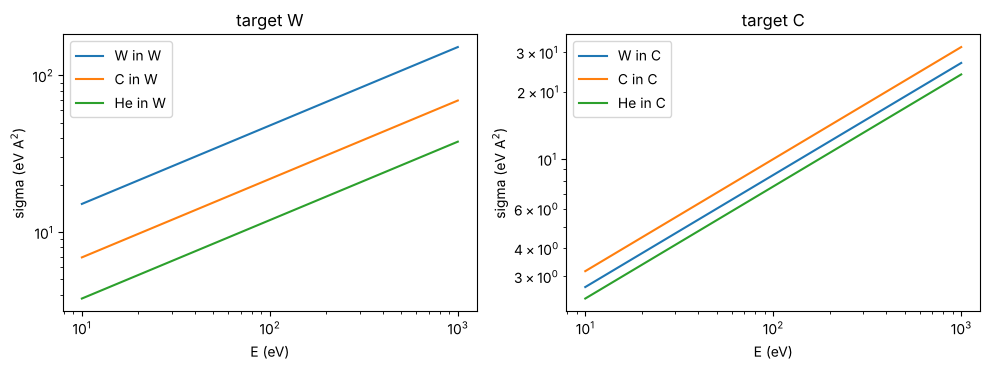

In [9]:
# stopping cross sections of the basis, and a 50/50 WC table built from it
import numpy as np, matplotlib.pyplot as plt
rows = [l.split() for l in open("basis_nb.dat") if l.strip() and not l.startswith("#")]
head = [l for l in open("basis_nb.dat") if l.startswith("# E_eV")][0].split()[1:]
data = np.array(rows, float)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for j, name in enumerate(head[1:], 1):
    proj, targ = name.split("@")
    ax[0 if targ == "W" else 1].loglog(data[:, 0], data[:, j], label=proj + " in " + targ)
for a, t in zip(ax, ("W", "C")):
    a.set_xlabel("E (eV)"); a.set_ylabel("sigma (eV A$^2$)"); a.set_title("target " + t); a.legend()
plt.tight_layout(); plt.show()

In [10]:
sys.argv = [SCRIPT, "table", "--basis", "basis_nb.dat", "--types", "W", "C", "He",
            "--target", "W:0.5,C:0.5", "--rho", "15.63", "-o", "elstop_WC_nb.table"]
main()
print(open("elstop_WC_nb.table").read()[:600])

wrote elstop_WC_nb.table  types W C He  n W=0.04806 C=0.04806
  S_e(  10 eV): W=0.857  C=0.484  He=0.296 eV/A
  S_e( 100 eV): W=2.711  C=1.531  He=0.937 eV/A
  S_e( 300 eV): W=4.696  C=2.652  He=1.623 eV/A
  S_e(1000 eV): W=8.574  C=4.842  He=2.963 eV/A
# fix electron/stopping table (units metal): E(eV), then S_e(eV/A) per atom type
# types: W C He   n(atoms/A^3): C=0.04806 W=0.04806
# basis range 10-1000 eV; outside it S_e is extended as sqrt(E)
     1.00000   2.711214e-01   1.531320e-01   9.370430e-02
     1.05234   2.781257e-01   1.570881e-01   9.612510e-02
     1.10741   2.853109e-01   1.611464e-01   9.860844e-02
     1.16537   2.926818e-01   1.653095e-01   1.011559e-01
     1.22636   3.002430e-01   1.695802e-01   1.037692e-01
     1.29054   3.079997e-01   1.739612e-01   1.064501e-01
     1.35809   3.159567e-01   1.784554e-01   1.092001e-
